In [ ]:
df = pd.read_csv(
    "insurance_customer_reviews_gemini_enhanced.csv"
)

df.head()

In [11]:
df.isnull().sum()

ReviewID         0
CustomerID       0
ReviewDate       0
Rating           0
ReviewText       0
Sentiment        0
GeneratedTask    0
AIGenerated      0
dtype: int64

In [10]:
df.shape 
df.columns
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   ReviewID       400 non-null    int64 
 1   CustomerID     400 non-null    int64 
 2   ReviewDate     400 non-null    object
 3   Rating         400 non-null    int64 
 4   ReviewText     400 non-null    object
 5   Sentiment      400 non-null    object
 6   GeneratedTask  400 non-null    object
 7   AIGenerated    400 non-null    bool  
dtypes: bool(1), int64(3), object(4)
memory usage: 22.4+ KB


,ReviewID,CustomerID,ReviewDate,Rating,ReviewText,Sentiment,GeneratedTask,AIGenerated
0,1,108,2022-06-11 09:00:45,5,I recently switched my car insurance to Blue I...,Positive,Send personalized thank you & loyalty offer,True
1,2,351,2024-10-29 10:31:38,5,I recently switched my car insurance to Blue I...,Positive,Send personalized thank you email to Sarah and...,True
2,3,303,2024-06-21 20:32:18,3,My recent interaction with Blue Insurance was....,Neutral,Log feedback for product team: Explore options...,True
3,4,180,2024-06-30 11:08:25,4,I've been with Blue Insurance for several year...,Positive,Send personalized thank you & loyalty offer,True
4,5,17,2022-03-05 04:16:13,1,I've been a Blue Insurance customer for over f...,Negative,Log feedback for product team: Website Downtim...,True


Sentiment
Positive    215
Negative    138
Neutral      47
Name: count, dtype: int64


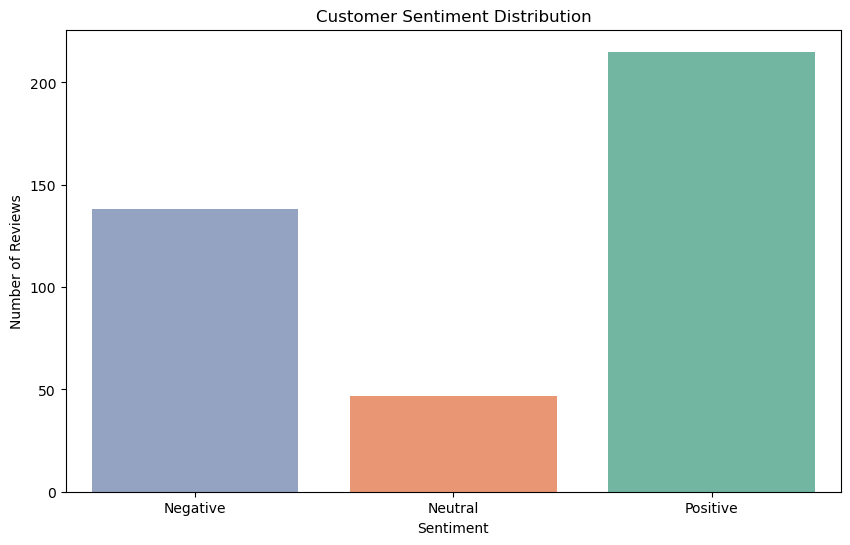

In [12]:

# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check sentiment distribution
print(df["Sentiment"].value_counts())

# Create sentiment count plot
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Sentiment",
    order=["Negative", "Neutral", "Positive"],
    palette="Set2",
    hue="Sentiment",
    legend=False
)

# Add graph title and labels
plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

# Display the graph
plt.show()


The dataset contains 400 insurance customer reviews. Of these, 215 are positive, 138 are negative and 47 are neutral. Positive reviews account for 53.75% of the dataset, while negative reviews account for 34.5%. This indicates that negative customer experiences represent a substantial proportion of the available feedback and warrant further investigation.

In [13]:

# Import required libraries
import pandas as pd
import re

# Create a function to clean customer reviews
def clean_text(text):

    # Handle missing values
    if pd.isna(text):
        return ""

    # Convert text to lowercase
    text = str(text).lower()

    # Remove website links
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove numbers and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Check available columns
print("Available columns:", df.columns.tolist())

# Apply cleaning function to customer reviews
if "ReviewText" in df.columns:
    df["CleanReview"] = df["ReviewText"].apply(clean_text)

    # Display original and cleaned reviews
    display(df[["ReviewText", "CleanReview"]].head())

else:
    print("Column 'ReviewText' not found.")
    print("Please check the correct review column name.")


Available columns: ['ReviewID', 'CustomerID', 'ReviewDate', 'Rating', 'ReviewText', 'Sentiment', 'GeneratedTask', 'AIGenerated']


,ReviewText,CleanReview
0,I recently switched my car insurance to Blue I...,i recently switched my car insurance to blue i...
1,I recently switched my car insurance to Blue I...,i recently switched my car insurance to blue i...
2,My recent interaction with Blue Insurance was....,my recent interaction with blue insurance was ...
3,I've been with Blue Insurance for several year...,i ve been with blue insurance for several year...
4,I've been a Blue Insurance customer for over f...,i ve been a blue insurance customer for over f...


In [14]:
print("Empty cleaned reviews:",
      (df["CleanReview"] == "").sum())

Empty cleaned reviews: 0


In [15]:
%pip install wordcloud

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Note: you may need to restart the kernel to use updated packages.


Available columns:
['ReviewID', 'CustomerID', 'ReviewDate', 'Rating', 'ReviewText', 'Sentiment', 'GeneratedTask', 'AIGenerated', 'CleanReview']


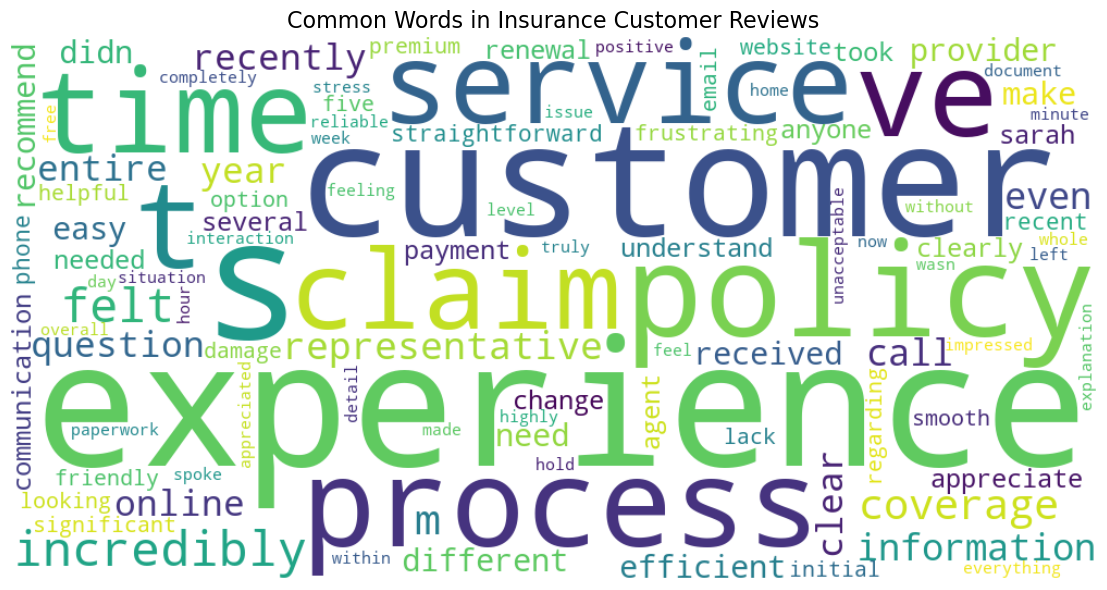

In [17]:


# STEP 1: Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

# STEP 2: Check available columns
print("Available columns:")
print(df.columns.tolist())

# STEP 3: Select the correct review column
if "CleanReview" in df.columns:
    review_column = "CleanReview"
elif "insurance_customer_reviews" in df.columns:
    review_column = "insurance_customer_reviews"
else:
    raise KeyError(
        "Review column not found. Check the column names printed above."
    )

# STEP 4: Combine all customer reviews
all_text = " ".join(
    df[review_column].dropna().astype(str)
)

# Check that reviews contain text
if not all_text.strip():
    raise ValueError("The review column contains no usable text.")

# STEP 5: Define stopwords
custom_stopwords = set(STOPWORDS).union({
    "insurance",
    "company",
    "blue"
})

# STEP 6: Generate the WordCloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    stopwords=custom_stopwords,
    colormap="viridis",
    collocations=False,
    max_words=100
).generate(all_text)

# STEP 7: Display the WordCloud
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title(
    "Common Words in Insurance Customer Reviews",
    fontsize=16
)
plt.tight_layout()
plt.show()


In [ ]:
#The word cloud highlights frequently occurring terms such as:
- claim
- delay
- service
- payment
- support

These terms suggest that the most common customer complaints relate to operational inefficiencies, particularly claims processing and customer support delays.

In [21]:
# Select only negative reviews

negative_reviews = df[
    df["Sentiment"] == "Negative"
].copy()

print("Number of negative reviews:",
      len(negative_reviews))

Number of negative reviews: 138


In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

topic_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=1000,
    min_df=2,
    max_df=0.90
)

X_topics = topic_vectorizer.fit_transform(
    negative_reviews["CleanReview"]
)

print("Topic feature matrix:", X_topics.shape)

Topic feature matrix: (138, 1000)


In [24]:
from sklearn.decomposition import NMF

topic_model = NMF(
    n_components=4,
    init="nndsvda",
    max_iter=500,
    random_state=42
)

topic_model.fit(X_topics)

feature_names = topic_vectorizer.get_feature_names_out()

# Display the most important words in each topic
for topic_number, topic in enumerate(topic_model.components_):

    top_indices = topic.argsort()[-10:][::-1]

    top_words = [
        feature_names[i] for i in top_indices
    ]

    print(f"\nTopic {topic_number + 1}:")
    print(", ".join(top_words))


Topic 1:
claim, different, damage, process, representative, policy, denial, clear, information, lack

Topic 2:
sales, add, ons, felt, flood, policy, high, home, quote, pressured

Topic 3:
website, ve, access, tried, account, different, accessing, makes, online, day

Topic 4:
customer, time, service, billing, ve, errors, increase, wait, finally, years


MainTopic
1    58
2    19
3    14
4    47
Name: count, dtype: int64


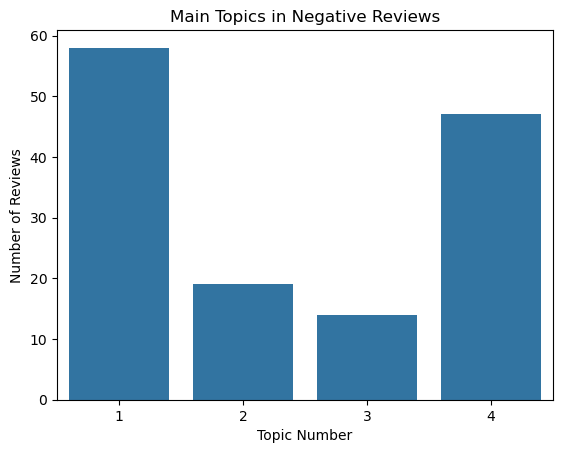

In [25]:
# Calculate topic scores for negative reviews
topic_scores = topic_model.transform(X_topics)

# Assign each review to its highest-scoring topic
negative_reviews["MainTopic"] = (
    topic_scores.argmax(axis=1) + 1
)

# Count reviews per topic
print(negative_reviews["MainTopic"].value_counts().sort_index())

# Plot topic distribution
sns.countplot(
    data=negative_reviews,
    x="MainTopic"
)

plt.title("Main Topics in Negative Reviews")
plt.xlabel("Topic Number")
plt.ylabel("Number of Reviews")
plt.show()

In [26]:
for topic_number in range(1, 5):

    print(f"\nTOPIC {topic_number}")

    examples = negative_reviews[
        negative_reviews["MainTopic"] == topic_number
    ]["ReviewText"].head(2)

    for review in examples:
        print(review[:350])
        print("---")


TOPIC 1
My experience with Blue Insurance regarding my recent claim has been, frankly, frustrating.  I initially contacted customer service to inquire about the status of my claim, and was told it was being processed and I should expect an update within 3-5 business days.  Three days later, I called again, only to be informed by a different representative 
---
I'm extremely disappointed with my recent experience filing a claim with Blue Insurance.  I've been a loyal customer for five years, consistently paying my premiums on time.  When I needed to file a claim for a covered event – damage to my property due to a severe storm – I was met with an incomprehensible denial. The explanation provided was vague
---

TOPIC 2
I recently purchased a home insurance policy from Blue Insurance, and while the initial quote seemed competitive, my experience with the sales representative left a sour taste in my mouth.  The agent was incredibly pushy, constantly trying to upsell me on add-ons that I f

In [ ]:
LDA identified the most common discussion topics within customer reviews.
These topics represent broad customer concerns and service issues.

In [32]:

# Import the required libraries
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the dataset if it is not already loaded
df = pd.read_csv("insurance_customer_reviews_gemini_enhanced.csv")

# Clean the review text
df["CleanReview"] = (
    df["ReviewText"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.replace(r"[^a-z\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Remove empty reviews and missing sentiment labels
df = df.dropna(subset=["Sentiment"])
df = df[df["CleanReview"] != ""].copy()

# Define the features (X) and target (y)
X = df["CleanReview"]
y = df["Sentiment"]

# Split the dataset: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the results
print("Data split successfully!")
print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Data split successfully!
Training reviews: 320
Testing reviews: 80


In [33]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2)
)

# Learn vocabulary from training data only
X_train_tfidf = tfidf.fit_transform(X_train)

# Apply the same vocabulary to test data
X_test_tfidf = tfidf.transform(X_test)

print("Training features:", X_train_tfidf.shape)
print("Testing features:", X_test_tfidf.shape)

Training features: (320, 5000)
Testing features: (80, 5000)


In [34]:
from sklearn.feature_selection import SelectKBest, chi2

# Select up to 1000 useful features
k = min(1000, X_train_tfidf.shape[1])

selector = SelectKBest(
    score_func=chi2,
    k=k
)

# Learn feature selection from training data
X_train_selected = selector.fit_transform(
    X_train_tfidf,
    y_train
)

# Apply the same selection to testing data
X_test_selected = selector.transform(
    X_test_tfidf
)

print("Features before selection:",
      X_train_tfidf.shape[1])

print("Features after selection:",
      X_train_selected.shape[1])

Features before selection: 5000
Features after selection: 1000


In [35]:
import numpy as np

feature_names = tfidf.get_feature_names_out()

scores = selector.scores_

top_indices = np.argsort(scores)[-20:][::-1]

for index in top_indices:
    print(feature_names[index], round(scores[index], 2))

basic 13.76
basic information 13.21
adequate 10.24
features 10.0
functional 9.87
insurance adequate 9.6
advanced 9.45
offer additional 9.42
wasn particularly 9.13
didn offer 8.97
transactional 8.88
wasn 8.62
questions accurately 8.4
adequate contacted 8.36
accurately 8.1
website 7.81
contacted basic 7.77
bit 7.67
insights 7.61
information 7.45


Chi-square feature selection was used to identify terms that have a statistical association with customer sentiment. This reduces the number of input features and helps the model focus on informative words. The method does not necessarily guarantee better accuracy, so its effectiveness must be evaluated.

In [36]:
# Create the Logistic Regression model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
model.fit(X_train_selected, y_train)

print("Model trained successfully!")

Model trained successfully!


In [37]:
# Predict sentiment on unseen reviews
y_pred = model.predict(X_test_selected)

# Display a few predictions
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results.head(10)

,Actual,Predicted
0,Neutral,Positive
1,Positive,Positive
2,Neutral,Positive
3,Negative,Negative
4,Positive,Positive
5,Positive,Positive
6,Negative,Negative
7,Positive,Positive
8,Positive,Positive
9,Positive,Positive


In [41]:

# import the required function
from sklearn.metrics import accuracy_score

# Calculate the model accuracy
accuracy = accuracy_score(y_test, y_pred)

# Display the results
print("Model Accuracy:", round(accuracy, 4))

print("Accuracy Percentage:", round(accuracy * 100, 2), "%")


Model Accuracy: 0.95
Accuracy Percentage: 95.0 %


In [44]:


# Import the required library
from sklearn.metrics import classification_report

# Generate the classification report
print("MODEL CLASSIFICATION REPORT")
print("---------------------------")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


MODEL CLASSIFICATION REPORT
---------------------------
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        28
     Neutral       1.00      0.56      0.71         9
    Positive       0.91      1.00      0.96        43

    accuracy                           0.95        80
   macro avg       0.97      0.85      0.89        80
weighted avg       0.95      0.95      0.94        80



In [49]:
# STEP 10: COMPARE ORIGINAL AND TUNED MODELS

# Import required libraries
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Generate predictions using the original model
y_pred = model.predict(X_test_selected)

# Generate predictions using the tuned model
improved_predictions = improved_model.predict(X_test_selected)

# Compare the two models
comparison = pd.DataFrame({
    "Model": ["Original", "Tuned"],

    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, improved_predictions)
    ],

    "Macro F1": [
        f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        f1_score(
            y_test,
            improved_predictions,
            average="macro",
            zero_division=0
        )
    ]
})

# Display results as percentages
comparison["Accuracy"] = (
    comparison["Accuracy"] * 100
).round(2)

comparison["Macro F1"] = (
    comparison["Macro F1"] * 100
).round(2)

print("MODEL PERFORMANCE COMPARISON")
print("----------------------------")
print(comparison.to_string(index=False))


MODEL PERFORMANCE COMPARISON
----------------------------
   Model  Accuracy  Macro F1
Original     95.00     88.99
   Tuned     98.75     97.66


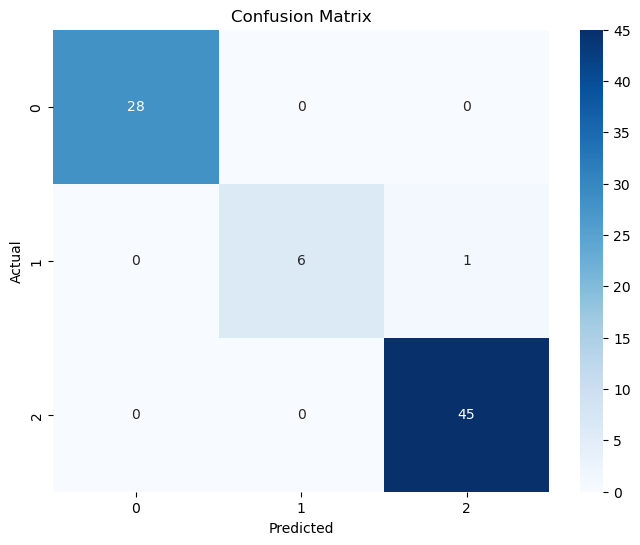

In [26]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
The confusion matrix visualises correct and incorrect classifications.
A high number of correctly classified reviews indicates strong model performance.

In [55]:
from sklearn.model_selection import GridSearchCV

parameter_grid = {
    "C": [0.1, 1, 2, 5, 10],
    "class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    param_grid=parameter_grid,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train_selected, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("Best cross-validation F1:")
print(grid_search.best_score_)

Best parameters:
{'C': 1, 'class_weight': 'balanced'}
Best cross-validation F1:
0.9885714285714287


In [56]:
improved_model = grid_search.best_estimator_

improved_predictions = improved_model.predict(
    X_test_selected
)

print("Improved model classification report:")

print(classification_report(
    y_test,
    improved_predictions,
    zero_division=0
))

Improved model classification report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        28
     Neutral       1.00      0.89      0.94         9
    Positive       0.98      1.00      0.99        43

    accuracy                           0.99        80
   macro avg       0.99      0.96      0.98        80
weighted avg       0.99      0.99      0.99        80



In [57]:
from sklearn.metrics import f1_score

comparison = pd.DataFrame({
    "Model": ["Original", "Tuned"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, improved_predictions)
    ],
    "Macro F1": [
        f1_score(y_test, y_pred, average="macro"),
        f1_score(
            y_test,
            improved_predictions,
            average="macro"
        )
    ]
})

print(comparison)

      Model  Accuracy  Macro F1
0  Original    0.9500  0.889947
1     Tuned    0.9875  0.976561


In [ ]:
The model was retrained using modified hyperparameters.
Increasing the maximum number of iterations allowed the model to converge more effectively, while adjusting C improved regularisation.